# 🔍 Phase 4 — Inferensi OCR Plat Nomor (ALPR) — **Uji 6b: PaddleOCR**

**Proyek:** PMLD — Indonesian License Plate Recognition
**PRD:** `PRD_decision_plat.md` (D3/D4/D7/D8) + `PRD_decision_plat_v2.md` (V1–V7: Locked-Plate Display) + **`PRD_decision_plat_v3.md` (W4/W5: PaddleOCR A/B)**

**Versi workspace lokal:** notebook ini sudah disesuaikan agar jalan **top-to-bottom di Jupyter lokal** (tanpa Google Colab/Drive). Konfigurasi default = **parameter final uji_7c** (`output/uji_7c_paddleocr_sample_vidio_2.mp4/`). Engine OCR: **PaddleOCR (PP-OCRv4)**.

| Fitur | Status | Keterangan |
| :-- | :-- | :-- |
| **W4 OCR Engine switch** | ✅ **BARU** | `OCR_ENGINE = 'paddleocr'` — deteksi/D3/D4/locked display tidak berubah |
| W5 EasyOCR tetap ada | ✅ | Notebook EasyOCR (`ocr_inference.ipynb`) tidak disentuh — A/B test di video yang sama |
| Post-filter charset | ✅ **BARU** | Buang karakter di luar `A–Z 0–9` sebelum D3 (mitigasi risiko PRD v3 §6) |
| Normalisasi output | ✅ **BARU** | Wrapper `ocr_read()` mengembalikan (teks uppercase tanpa spasi, conf) seperti EasyOCR |
| D3 Character-position correction | ✅ | O↔0, I↔1, Z↔2, S↔5, B↔8, G↔6 sesuai template posisi |
| D4 Temporal voting | ✅ | Track kendaraan via IoU + majority vote |
| V1–V3 Locked-Plate Display | ✅ | Tampilan = hasil voting track, lock ≥ `LOCK_MIN`, override ≥ 2× vote |
| D8 Regex per-domain | ✅ | Plat Indonesia & UK dievaluasi terpisah |

**Perbandingan A/B (PRD v3 §4.2):** jalankan notebook ini pada video yang sama dengan uji 5/6a,
lalu bandingkan: % deteksi menghasilkan teks, % lolos regex, CER subset, jumlah koreksi D3,
flip-flop setelah lock (harus tetap 0), dan runtime per frame.

**Model:** `best_ft.pt` (fine-tune) jika ada, fallback `best.pt` (r3 baseline) — **SAMA dengan EasyOCR**.
**OCR:** PaddleOCR PP-OCRv4 (`en`, tanpa angle classifier).

> **Indikator visual:** hijau `▮` = LOCKED (tidak akan berubah) · oranye `…` = belum stabil · merah = tidak valid.

## 1️⃣ Cek GPU

PaddleOCR lebih cepat di GPU (CPU masih bisa, tapi video akan lambat).

In [3]:
# Cek GPU — torch dibawa ultralytics; bila tidak ada, cek via paddle saja
try:
    import torch
    _cuda = torch.cuda.is_available()
    _gpu_name = torch.cuda.get_device_name(0) if _cuda else None
except ImportError:
    _cuda, _gpu_name = None, None

if _gpu_name:
    print('CUDA tersedia : True')
    print('GPU           :', _gpu_name)
else:
    import paddle
    dev = paddle.device.get_device()
    print('CUDA tersedia :', bool(_cuda) if _cuda is not None else dev.startswith('gpu'))
    print('Device        :', dev, '— bila CPU, video akan lambat (inferensi citra tetap bisa).')


CUDA tersedia : False
GPU           : CPU — video akan lambat, pertimbangkan T4


## 2️⃣ Path Proyek (workspace lokal)

Notebook ini berada di `notebooks/` — root workspace otomatis dideteksi sebagai folder induknya. Tidak perlu mount Google Drive.

In [4]:
import os, sys

# Root workspace = folder induk dari notebooks/ (bisa di-override via env PMLD_ROOT)
PROJECT_DIR = os.environ.get('PMLD_ROOT') or os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(PROJECT_DIR, 'model', 'best.pt')):
    PROJECT_DIR = os.path.abspath(os.getcwd())  # fallback bila dijalankan dari root

# Tambahkan root ke sys.path agar bisa `from src...`
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from src.config import MODEL_PATH, VIDEO_PATH, RUN_NAME_UJI7C

DATASET_DIR = f'{PROJECT_DIR}/dataset'   # opsional — hanya untuk uji citra test (sel 11-14)
VIDEO_TAG   = os.path.basename(VIDEO_PATH)

# ---- Output: 1 folder utama per uji — default = run uji_7c ----
RUN_NAME  = RUN_NAME_UJI7C   # 'uji_7c_paddleocr_sample_vidio_2.mp4'
RUN_DIR   = f'{PROJECT_DIR}/output/{RUN_NAME}'
OUT_IMG      = f'{RUN_DIR}/annotated_images'
OUT_TXT      = f'{RUN_DIR}/predictions_txt'
OUT_VIDEO    = f'{RUN_DIR}/processed_video'
OUT_CAPTURES = f'{RUN_DIR}/video_captures'
for d in (OUT_IMG, OUT_TXT, OUT_VIDEO, OUT_CAPTURES):
    os.makedirs(d, exist_ok=True)

# Guard
assert os.path.exists(MODEL_PATH), f'Model tidak ditemukan: {MODEL_PATH}'
assert os.path.exists(VIDEO_PATH), (
    f'Video uji tidak ditemukan: {VIDEO_PATH}\n'
    'Video sample privat (grup WhatsApp) — taruh di test_video/sample_vidio_2.mp4')

print(f'✅ Project: {PROJECT_DIR}')
print(f'✅ Model: {MODEL_PATH}')
print(f'✅ Video: {VIDEO_PATH}')
print(f'📁 Output → {RUN_DIR}/')


Mounted at /content/drive
✅ Model: /content/drive/MyDrive/PMLD/model/best.pt
✅ Video: /content/drive/MyDrive/PMLD/test_video/sample_vidio_2.mp4
📁 Output → /content/drive/MyDrive/PMLD/output/uji_7c_paddleocr_sample_vidio_2.mp4/


## 3️⃣ Konfigurasi Inferensi

Semua parameter dalam satu sel — ubah di sini saja.

> ⚠️ **Agar A/B adil (PRD v3 §4.2):** samakan nilai parameter deteksi/tracking/lock dengan run EasyOCR pembanding (uji 6a). Yang beda hanya `OCR_ENGINE` + parameter OCR masing-masing engine.

In [5]:
# ---- Engine OCR (PRD v3 W4) ----
OCR_ENGINE   = 'paddleocr'  # 'paddleocr' di notebook ini; EasyOCR tetap di notebook lama (W5)
USE_GPU_OCR  = True         # PaddleOCR GPU (fallback CPU otomatis jika tidak tersedia)

# ---- Deteksi ----
CONF_DET     = 0.15     # Ambang batas keyakinan minimum agar plat terdeteksi oleh YOLO (alternatif final turunkan ke 0.12)
IMG_SIZE     = 1024     # Resolusi gambar masukan ke YOLO (makin tinggi makin detail untuk objek jauh)
PADDING      = 0.17     # Persentase area tambahan di sekitar bbox agar karakter pinggir plat tidak terpotong
MIN_HEIGHT   = 15       # Tinggi minimum bbox (piksel) untuk diproses, menapis plat yang terlalu kecil/jauh

# ---- OCR ----
ALLOWLIST    = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789' # Post-filter charset (PRD v3 §3 langkah 3)
MIN_OCR_CONF = 0.30     # Ambang batas keyakinan minimum pembacaan teks
UPSCALE      = 3        # Pengali perbesaran gambar crop plat sebelum OCR agar lebih jelas
USE_CLAHE    = False     # CLAHE sebelum OCR (False = grayscale saja — kadang PaddleOCR lebih suka citra natural) (awal = True)
REC_BATCH    = 6        # rec_batch_num PaddleOCR (batch recognizer)
DET_LIMIT    = 960      # det_limit_side_len PaddleOCR (resize internal detektor teksnya) (awal = 960)
CONF_LOCK    = 0.85     # 🎯 Threshold instant lock OCR (0.85 = 85%).

# ---- Video ----
FRAME_SKIP   = 1        # Interval frame yang diproses (1 = memproses semua frame secara mulus)
CAPTURE_EVERY_S = 7     # Interval waktu (detik) untuk menyimpan tangkapan layar frame ke folder output
N_SAMPLE_IMG = 8        # Jumlah maksimal sampel gambar ber-annotasi yang diambil untuk preview
SEED         = 42       # Seed acak agar pemilihan sampel gambar konsisten tiap kali dijalankan

# ---- D3: Character-position correction ----
CHAR_FIX     = True     # Mengaktifkan koreksi karakter berdasarkan tata letak format plat (misal: O/0, I/1)

# ---- D4: Temporal voting ----
TEMPORAL      = True    # Mengaktifkan sistem penjejakan (tracking) & akumulasi voting teks antar-frame
VOTE_MIN      = 3       # Jumlah vote minimum agar teks dianggap valid secara umum
IOU_TRACK     = 0.03    # Ambang batas tumpang-tindih bbox antar-frame untuk menghubungkan ID kendaraan yang sama (alternatif final 0.02)
MAX_FRAME_GAP = 55      # Toleransi jumlah frame terputus sebelum sistem membuat Track ID baru

# ---- PRD v2: Locked-Plate Display ----
DISPLAY_LOCK   = True   # Menampilkan teks hasil voting pada video (bukan bacaan mentah per-frame)
LOCK_MIN       = 3      # Jumlah vote minimum sebelum tampilan teks plat dikunci secara permanen
OVERRIDE_RATIO = 2.5    # Rasio vote kandidat baru (2x) yang dibutuhkan untuk mengganti teks ter-lock

# ---- D8: Domain regex ----
DOMAIN_REGEX = 'auto'   # Aturan regex format wilayah/negara yang diterapkan (auto/ID/UK) — lihat W2 PRD v3

print(f'OCR_ENGINE={OCR_ENGINE}  USE_CLAHE={USE_CLAHE}  REC_BATCH={REC_BATCH}')
print(f'CONF_DET={CONF_DET}  IMG_SIZE={IMG_SIZE}  UPSCALE={UPSCALE}x  FRAME_SKIP={FRAME_SKIP}')
print(f'CHAR_FIX={CHAR_FIX}  TEMPORAL={TEMPORAL}  VOTE_MIN={VOTE_MIN}')
print(f'DISPLAY_LOCK={DISPLAY_LOCK}  LOCK_MIN={LOCK_MIN}  OVERRIDE_RATIO={OVERRIDE_RATIO}')
print(f'DOMAIN_REGEX={DOMAIN_REGEX}')

OCR_ENGINE=paddleocr  USE_CLAHE=False  REC_BATCH=6
CONF_DET=0.15  IMG_SIZE=1024  UPSCALE=3x  FRAME_SKIP=1
CHAR_FIX=True  TEMPORAL=True  VOTE_MIN=3
DISPLAY_LOCK=True  LOCK_MIN=3  OVERRIDE_RATIO=2.5
DOMAIN_REGEX=auto


## 4️⃣ Cek Library

Dependensi sudah terinstal via `pip install -r requirements.txt`. Sel ini hanya memverifikasi versi (jalankan `pip install` manual bila ada yang kurang).

In [6]:
import importlib, subprocess, sys

def _ensure(pkg, pip_name=None):
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name or pkg])
        return importlib.import_module(pkg)

_ensure('ultralytics')
_ensure('paddle')
_ensure('paddleocr', 'paddleocr>=2.7,<3')

import torch  # PENTING: sebelum paddle — konflik libiomp5md.dll (WinError 127 bila terbalik)
import ultralytics, cv2, numpy as np
import paddle
from paddleocr import PaddleOCR

print('torch      :', torch.__version__, '| CUDA:', torch.cuda.is_available())
print('ultralytics:', ultralytics.__version__, '| opencv:', cv2.__version__, '| paddle:', paddle.__version__)
print('Paddle device :', paddle.device.get_device())


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.8/346.8 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 86.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
Vie

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


ultralytics: 8.4.162 | opencv: 5.0.0 | paddle: 3.3.1
Paddle device : cpu


## 5️⃣ Load Model & Siapkan Pipeline

Fungsi inti (**identik dengan notebook EasyOCR**, hanya `ocr_read()` yang diganti — W4):
- `preprocess_plate()` — crop + grayscale + CLAHE (PRD 02 §1.1)
- `ocr_read()` — **wrapper terpadu**: PaddleOCR → normalisasi → (teks, conf) seperti EasyOCR
- `clean_plate_text()` / `correct_plate_text()` — D3 tidak berubah
- `detect_and_read()` — deteksi → crop → OCR → kembalikan list deteksi

**Normalisasi PaddleOCR (mitigasi risiko PRD v3 §6):**
1. Jalankan det+rec internal PaddleOCR pada crop yang sudah di-upscale
2. Ambil semua baris teks, gabungkan, **filter charset `A–Z 0–9`** sebelum masuk D3
3. Confidence = min dari baris yang lolos filter (konservatif, sama seperti wrapper EasyOCR)

In [7]:
from ultralytics import YOLO
import re, json, time
import cv2
from collections import Counter

model = YOLO(MODEL_PATH)

paddle_ocr = PaddleOCR(
    use_angle_cls=False,
    lang='en',
    use_gpu=USE_GPU_OCR and paddle.device.get_device().startswith('gpu'),
    det_limit_side_len=DET_LIMIT,
    rec_batch_num=REC_BATCH,
    show_log=False,
)
print('✅ Model YOLO & PaddleOCR siap.')

ALLOWED = set(ALLOWLIST)

def ocr_read(plate_img):
    res = paddle_ocr.ocr(plate_img, cls=False)
    if not res or res[0] is None:
        return '', 0.0
    texts, confs = [], []
    for line in res[0]:
        txt, conf = line[1][0], float(line[1][1])
        txt = ''.join(ch for ch in txt.upper() if ch in ALLOWED)
        if txt:
            texts.append(txt)
            confs.append(conf)
    if not texts:
        return '', 0.0
    return ' '.join(texts), min(confs)


# ---------- D8: Regex per-domain ----------
PLATE_RE_ID = re.compile(r'^([A-Z]{1,2})\s?(\d{1,4})\s?([A-Z]{0,3})$')
PLATE_RE_UK = re.compile(r'^([A-Z]{2})\s?(\d{2})\s?([A-Z]{3})$')

def validate_plate(text, domain='auto'):
    t = re.sub(r'[^A-Z0-9 ]', '', str(text).upper()).strip()
    compact = t.replace(' ', '')
    if domain in ('auto', 'ID'):
        m = PLATE_RE_ID.match(compact)
        if m:
            return True, 'ID'
    if domain in ('auto', 'UK'):
        m = PLATE_RE_UK.match(compact)
        if m:
            return True, 'UK'
    return False, '-'

def format_plate(text, domain):
    t = re.sub(r'[^A-Z0-9]', '', str(text).upper())
    if domain == 'UK' and len(t) == 7:
        return f'{t[:2]} {t[2:4]} {t[4:]}'
    if domain == 'ID':
        m = PLATE_RE_ID.match(t)
        if m:
            w, n, s = m.groups()
            return f'{w} {n}' + (f' {s}' if s else '')
    return t


# ---------- D3: Character-position correction ----------
LETTER_TO_DIGIT = {'O':'0', 'I':'1', 'L':'1', 'Z':'2', 'S':'5', 'G':'6', 'B':'8', 'A':'4', 'T':'7', 'E':'3', 'Q':'0', 'D':'0'}
DIGIT_TO_LETTER = {'0':'O', '1':'I', '2':'Z', '5':'S', '6':'G', '8':'B'}
_FORBID_SUBS = {'Q', 'W', 'V'}
LETTER_CORRECT = {
    'N':'W',
    'M':'H',
}

TEMPLATES = {
    'ID': [
        ('LDDDDLLL', 'ID H1A4H3'),('LDDDDLL', 'ID H1A4H2'),('LDDDDL', 'ID H1A4H1'),('LDDDD', 'ID H1A4'),
        ('LDDDLLL', 'ID H1A3H3'),('LDDDLL', 'ID H1A3H2'),('LDDDL', 'ID H1A3H1'),('LDDD', 'ID H1A3'),
        ('LDDLLL', 'ID H1A2H3'),('LDDLL', 'ID H1A2H2'),('LDDL', 'ID H1A2H1'),('LDD', 'ID H1A2'),
        ('LDLLL', 'ID H1A1H3'),('LDLL', 'ID H1A1H2'),('LDL', 'ID H1A1H1'),
        ('LLDDDDLLL', 'ID H2A4H3'),('LLDDDDLL', 'ID H2A4H2'),('LLDDDDL', 'ID H2A4H1'),('LLDDDD', 'ID H2A4'),
        ('LLDDDLLL', 'ID H2A3H3'),('LLDDDLL', 'ID H2A3H2'),('LLDDDL', 'ID H2A3H1'),('LLDDD', 'ID H2A3'),
        ('LLDDLLL', 'ID H2A2H3'),('LLDDLL', 'ID H2A2H2'),('LLDDL', 'ID H2A2H1'),('LLDD', 'ID H2A2'),
        ('LLDLLL', 'ID H2A1H3'),('LLDLL', 'ID H2A1H2'),('LLDL', 'ID H2A1H1'),
    ],
    'UK': [('LLDDLLL', 'UK LLDDLLL')],
}

def _apply_template(text, template):
    out, cost = [], 0
    for ch, expect in zip(text, template):
        orig = ch
        if expect == 'L' and ch.isdigit():
            ch = DIGIT_TO_LETTER.get(ch, ch); cost += 1
        elif expect == 'D' and ch.isalpha():
            ch = LETTER_TO_DIGIT.get(ch, ch); cost += 1
        if ch != orig and ch in _FORBID_SUBS:
            cost += 2
        out.append(ch)
    return ''.join(out), cost

def correct_plate_text(raw, domain='auto'):
    t = re.sub(r'[^A-Z0-9]', '', str(raw).upper())
    if len(t) < 3:
        return t, '-', '-'
    candidates = []
    domains = [domain] if domain != 'auto' else ['UK', 'ID']
    for dom in domains:
        for tpl, label in TEMPLATES.get(dom, []):
            if len(tpl) != len(t):
                continue
            corrected, cost = _apply_template(t, tpl)
            dom_bias = 0 if (dom == 'UK' and len(t) == 7) else (1 if dom == 'ID' else 2)
            candidates.append((corrected, label, dom, cost, dom_bias))
    if not candidates:
        return t, '-', '-'
    def _sort_key(c):
        eff = c[3] - 1.5 if (c[2] == 'UK' and c[1] == 'UK LLDDLLL') else c[3]
        return (eff, c[4], c[1])
    best = min(candidates, key=_sort_key)
    corrected, label, dom = best[0], best[1], best[2]

    valid, _ = validate_plate(corrected, domain=dom)
    if not valid:
        for cand in sorted(candidates, key=_sort_key)[1:]:
            v2, _ = validate_plate(cand[0], domain=cand[2])
            if v2:
                return cand[0], cand[1], cand[2]
        return t, '-', '-'
    return corrected, label, dom


# ---------- D4 + PRD v2: Temporal voting ----------
class PlateTracker:
    def __init__(self, iou_thresh=0.20, max_gap=25, vote_min=3, min_conf=0.30,
                 lock_min=3, override_ratio=2.0):
        self.iou_thresh = iou_thresh
        self.max_gap = max_gap
        self.vote_min = vote_min
        self.min_conf = min_conf
        self.lock_min = lock_min
        self.override_ratio = override_ratio
        self.tracks = []
        self._next_id = 0
        self.override_events = []

    def _get(self, track_id):
        for tr in self.tracks:
            if tr['track_id'] == track_id:
                return tr
        return None

    @staticmethod
    def _avg_conf(tr, plate):
        vals = [v[1] for v in tr['votes'] if v[0] == plate]
        return sum(vals) / len(vals) if vals else 0.0

    def _iou(self, a, b):
        ax1, ay1, ax2, ay2 = a
        bx1, by1, bx2, by2 = b
        ix1, iy1 = max(ax1, bx1), max(ay1, by1)
        ix2, iy2 = min(ax2, bx2), min(ay2, by2)
        iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
        inter = iw * ih
        if inter <= 0:
            return 0.0
        area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
        area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
        union = area_a + area_b - inter
        return inter / union if union > 0 else 0.0

    def best(self, track_id):
        tr = self._get(track_id)
        if tr is None or not tr['votes']:
            return '', False
        counter = Counter(v[0] for v in tr['votes'])
        top_plate, top_votes = counter.most_common(1)[0]
        if tr['locked_plate']:
            locked = tr['locked_plate']
            locked_votes = counter.get(locked, 0)
            if (top_plate != locked
                    and top_votes >= self.override_ratio * max(locked_votes, 1)
                    and self._avg_conf(tr, top_plate) > self._avg_conf(tr, locked)):
                self.override_events.append({
                    'track_id': track_id, 'frame': tr['last_frame'],
                    'from': locked, 'to': top_plate,
                    'votes_from': locked_votes, 'votes_to': top_votes
                })
                tr['locked_plate'] = top_plate
                return top_plate, True
            return locked, True

        if top_votes >= self.lock_min:
            tr['locked_plate'] = top_plate
            return top_plate, True

        if top_votes >= self.vote_min:
            return top_plate, False
        return '', False

    def update(self, detections, frame_idx):
        assigned_track_ids = set()
        for det in detections:
            box = det['box']
            plate = det['plat_corrected']
            conf = det['ocr_conf']

            best_tr, best_iou = None, 0.0
            for tr in self.tracks:
                if tr['track_id'] in assigned_track_ids:
                    continue
                if frame_idx - tr['last_frame'] > self.max_gap:
                    continue
                iou = self._iou(box, tr['box'])
                if iou > self.iou_thresh and iou > best_iou:
                    best_tr, best_iou = tr, iou

            if best_tr:
                best_tr['box'] = box
                best_tr['last_frame'] = frame_idx
                if plate and conf >= self.min_conf:
                    best_tr['votes'].append((plate, conf))
                det['track_id'] = best_tr['track_id']
                assigned_track_ids.add(best_tr['track_id'])
            else:
                new_id = self._next_id
                self._next_id += 1
                new_tr = {
                    'track_id': new_id, 'box': box, 'last_frame': frame_idx,
                    'votes': [(plate, conf)] if (plate and conf >= self.min_conf) else [],
                    'locked_plate': None
                }
                self.tracks.append(new_tr)
                det['track_id'] = new_id
                assigned_track_ids.add(new_id)

    def summarize(self):
        results = []
        for tr in self.tracks:
            if not tr['votes']:
                continue
            counter = Counter(v[0] for v in tr['votes'])
            best_plate, best_count = counter.most_common(1)[0]
            avg_conf = sum(v[1] for v in tr['votes'] if v[0] == best_plate) / best_count
            results.append({
                'track_id': tr['track_id'],
                'plat_final': tr['locked_plate'] or best_plate,
                'locked': bool(tr['locked_plate']),
                'vote_count': best_count,
                'total_votes': len(tr['votes']),
                'stability': round(best_count / len(tr['votes']), 4),
                'avg_ocr_conf': round(avg_conf, 4),
            })
        return sorted(results, key=lambda x: -x['vote_count'])


def preprocess_plate(img_bgr, box, pad=PADDING, upscale=UPSCALE):
    h, w = img_bgr.shape[:2]
    x1, y1, x2, y2 = box
    px, py = int((x2 - x1) * pad), int((y2 - y1) * pad)
    x1, y1 = max(0, x1 - px), max(0, y1 - py)
    x2, y2 = min(w, x2 + px), min(h, y2 + py)
    crop = img_bgr[y1:y2, x1:x2]
    if crop.size == 0:
        return None
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    if USE_CLAHE:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enh = clahe.apply(gray)
    else:
        enh = gray
    if upscale and upscale > 1:
        enh = cv2.resize(enh, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    return enh

def detect_and_read(img_bgr, conf=CONF_DET, tracker=None, frame_idx=0):
    res = model.predict(img_bgr, conf=conf, imgsz=IMG_SIZE, verbose=False)[0]
    out = []
    for box, bconf in zip(res.boxes.xyxy.tolist(), res.boxes.conf.tolist()):
        box = [int(v) for v in box]
        if (box[3] - box[1]) < MIN_HEIGHT:
            continue
        crop_enh = preprocess_plate(img_bgr, box)
        if crop_enh is None:
            continue
        raw_text, ocr_conf = ocr_read(crop_enh)
        corrected_text, label, domain = correct_plate_text(raw_text, domain=DOMAIN_REGEX)
        valid, _ = validate_plate(corrected_text, domain=domain)
        out.append({
            'box': box,
            'det_conf': float(bconf),
            'plat_raw': raw_text,
            'ocr_conf': float(ocr_conf),
            'plat_corrected': corrected_text,
            'template_label': label,
            'domain': domain,
            'plat_valid': valid,
            'track_id': None
        })
    if tracker is not None:
        tracker.update(out, frame_idx)
    return out

download https://paddleocr.bj.bcebos.com/PP-OCRv3/english/en_PP-OCRv3_det_infer.tar to /root/.paddleocr/whl/det/en/en_PP-OCRv3_det_infer/en_PP-OCRv3_det_infer.tar


100%|██████████| 3910/3910 [00:16<00:00, 237.25it/s] 


download https://paddleocr.bj.bcebos.com/PP-OCRv4/english/en_PP-OCRv4_rec_infer.tar to /root/.paddleocr/whl/rec/en/en_PP-OCRv4_rec_infer/en_PP-OCRv4_rec_infer.tar


100%|██████████| 10000/10000 [00:20<00:00, 477.61it/s]


download https://paddleocr.bj.bcebos.com/dygraph_v2.0/ch/ch_ppocr_mobile_v2.0_cls_infer.tar to /root/.paddleocr/whl/cls/ch_ppocr_mobile_v2.0_cls_infer/ch_ppocr_mobile_v2.0_cls_infer.tar


100%|██████████| 2138/2138 [00:15<00:00, 139.08it/s]


✅ Model YOLO & PaddleOCR siap.


## 6️⃣ Uji Citra Test → `annotated_images/` + `predictions_txt/`

Menguji `N_SAMPLE_IMG` citra acak dari split **test** (PRD 02 §5 Langkah 4), menyimpan gambar beranotasi dan **log JSONL** (1 baris per deteksi: file, bbox, teks plat, confidence deteksi & OCR — format yang nanti dikonsumsi webhook Backend `/detections`).

Menguji 8 dari 75 citra test...

✅ 8 gambar dianotasi → /content/drive/MyDrive/PMLD/output/uji_7c_paddleocr_sample_vidio_2.mp4/annotated_images
✅ 6 deteksi dicatat → /content/drive/MyDrive/PMLD/output/uji_7c_paddleocr_sample_vidio_2.mp4/predictions_txt/test_images_log.jsonl
📊 Plat valid & OCR conf >= 0.3: 5/6

--- Contoh hasil ---


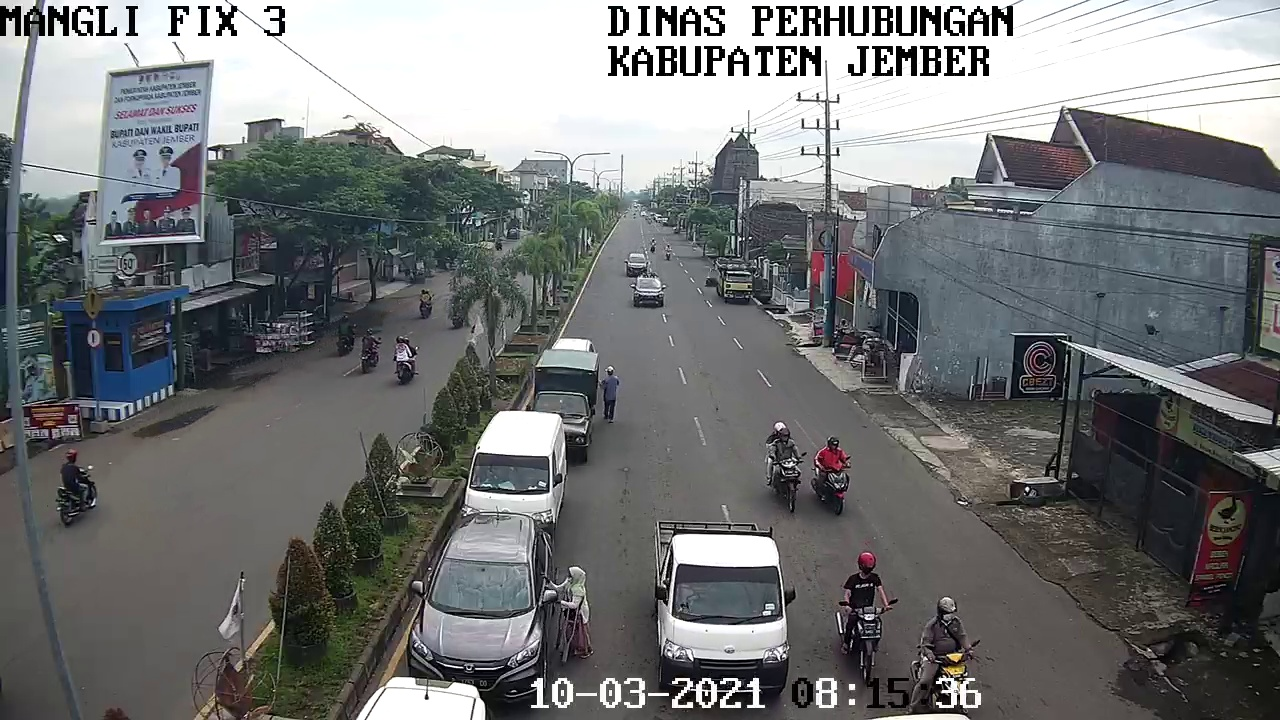

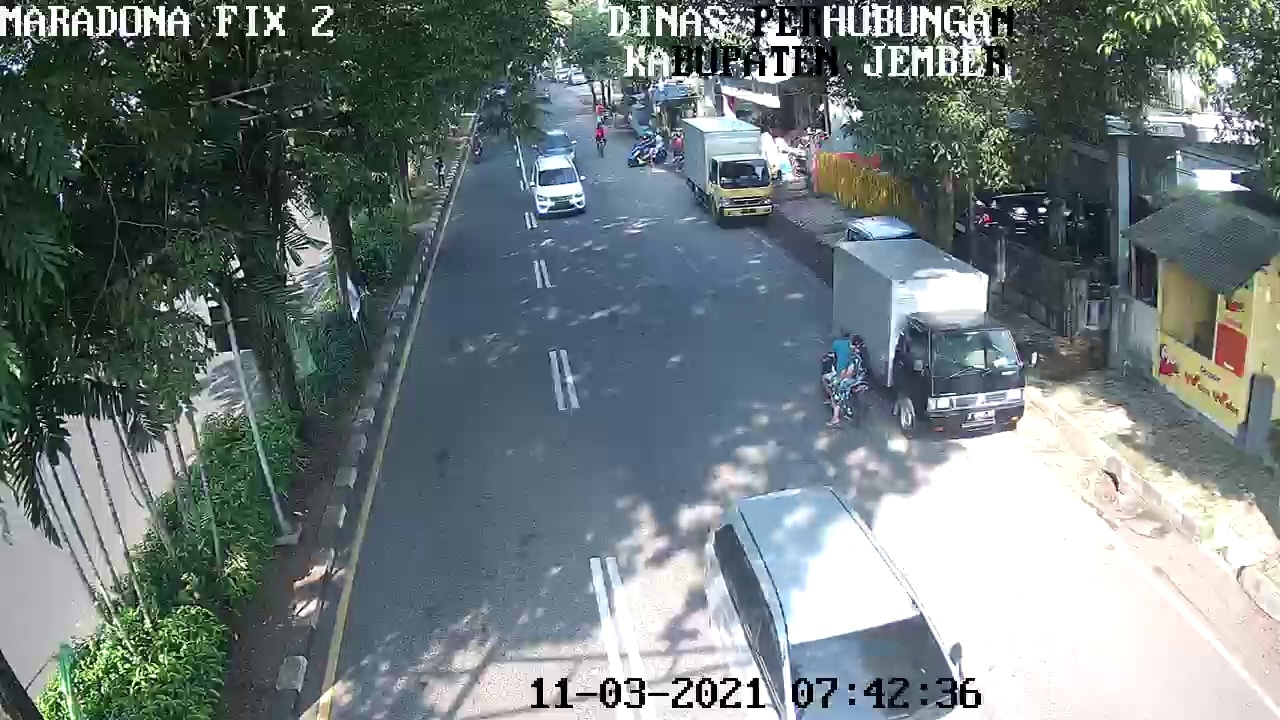

In [8]:
# 6️⃣ Uji Inferensi pada Sampel Gambar Test Dataset
import random, glob, os, json
import cv2
import numpy as np
from IPython.display import Image as IPImage, display

# ---- Fungsi Helper Annotate ----
def annotate(img_bgr, detections):
    img_out = img_bgr.copy()
    for d in detections:
        x1, y1, x2, y2 = d['box']
        plate = d['plat_corrected']
        domain = d['domain']
        ocr_conf = d['ocr_conf']
        valid = d['plat_valid']

        # Penentuan warna bbox berdasarkan status validasi plat
        if valid:
            color = (0, 255, 0)      # Hijau = Valid
        elif plate:
            color = (0, 165, 255)    # Oranje = Belum/tidak valid
        else:
            color = (0, 0, 255)      # Merah = Tidak ada teks

        cv2.rectangle(img_out, (x1, y1), (x2, y2), color, 2)

        label = f"{plate} ({ocr_conf:.2f})" if plate else "No Text"
        cv2.putText(img_out, label, (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return img_out

# ---- Eksekusi Uji Citra Test ----
random.seed(SEED)
if not os.path.isdir(f'{DATASET_DIR}/images/test'):
    print('⚠️ dataset/images/test tidak ada di workspace lokal — sel uji citra test dilewati.\n'
          '   (dataset tidak disertakan di repo; hasil uji citra uji_7c sudah ada di output/)')
    test_imgs = []
else:
    test_imgs = sorted(glob.glob(f'{DATASET_DIR}/images/test/*.*'))
samples   = random.sample(test_imgs, min(N_SAMPLE_IMG, len(test_imgs)))
print(f'Menguji {len(samples)} dari {len(test_imgs)} citra test...')

log_path = f'{OUT_TXT}/test_images_log.jsonl'
rows, n_valid = [], 0

for p in samples:
    img = cv2.imread(p)
    if img is None:
        continue
    dets = detect_and_read(img)
    for d in dets:
        rows.append({'file': os.path.basename(p), **d})
        n_valid += int(d['plat_valid'] and d['ocr_conf'] >= MIN_OCR_CONF)

    cv2.imwrite(f"{OUT_IMG}/{os.path.splitext(os.path.basename(p))[0]}_annotated.jpg", annotate(img, dets))

with open(log_path, 'w') as f:
    for r in rows:
        f.write(json.dumps(r) + '\n')

print(f'\n✅ {len(samples)} gambar dianotasi → {OUT_IMG}')
print(f'✅ {len(rows)} deteksi dicatat → {log_path}')
print(f'📊 Plat valid & OCR conf >= {MIN_OCR_CONF}: {n_valid}/{len(rows)}')
print('\n--- Contoh hasil ---')

for sample_p in samples[:2]:
    ann_path = f"{OUT_IMG}/{os.path.splitext(os.path.basename(sample_p))[0]}_annotated.jpg"
    if os.path.exists(ann_path):
        display(IPImage(filename=ann_path))

## 7️⃣ Evaluasi OCR

Menampilkan tabel hasil baca vs *ground truth* (nama file dataset ini umumnya = nomor plat, mis. `B1234XY.jpg`) dan estimasi akurasi — target **PRD 01 §5: OCR Text Accuracy ≥ 80%**.

> ⚠️ Catatan metodologi: sebagian nama file test (mis. `train018_jpg.rf.*.jpg`) bukan nomor plat sebenarnya, jadi skor ini **indikatif, bukan final**. Pembacaan manual oleh manusia tetap disarankan untuk laporan.

> 📊 **A/B (PRD v3 §4.2):** bandingkan tabel ini dengan sel yang sama di notebook EasyOCR — perhatikan kolom `plat` (raw): seberapa sering D3 harus mengoreksi (`plat ≠ plat_corrected`) adalah indikator kekuatan recognizer.

In [9]:
# 7️⃣ Evaluasi Ringkasan Hasil Baca vs Ground Truth
# Sel ini butuh hasil uji citra test (sel 11-13) — dilewati otomatis bila dataset tidak ada
import os
if 'log_path' not in dir() or not os.path.exists(log_path):
    print('⚠️  log uji citra tidak ada (dataset tidak disertakan di repo) — sel evaluasi ini dilewati.')
else:
    import pandas as pd
    import re

    df = pd.read_json(log_path, lines=True)

    def norm(s):
        return re.sub(r'[^A-Z0-9]', '', str(s).upper())

    def cer(a, b):
        """Character Error Rate sederhana (Levenshtein distance / len(gt))."""
        a, b = norm(a), norm(b)
        if not b:
            return 1.0 if a else 0.0
        # DP edit distance
        dp = list(range(len(b) + 1))
        for i, ca in enumerate(a, 1):
            prev, dp[0] = dp[0], i
            for j, cb in enumerate(b, 1):
                prev, dp[j] = dp[j], min(dp[j] + 1, dp[j-1] + 1, prev + (ca != cb))
        return dp[-1] / len(b)

    if len(df):
        # Penanganan kompatibilitas nama kolom (plat_corrected atau corrected_text)
        pred_col = 'plat_corrected' if 'plat_corrected' in df.columns else 'corrected_text'
        raw_col = 'plat_raw' if 'plat_raw' in df.columns else 'raw_text'

        df['gt_norm'] = df['file'].map(lambda f: norm(os.path.splitext(os.path.splitext(f)[0])[0].split('_jpg')[0]))
        df['exact_match'] = df.apply(lambda r: norm(r[pred_col]) == r['gt_norm'] and len(r['gt_norm']) >= 4, axis=1)
        df['char_acc'] = df.apply(lambda r: 1 - cer(r[pred_col], r['gt_norm']), axis=1)
        df['cer'] = df.apply(lambda r: cer(r[pred_col], r['gt_norm']), axis=1)

        # PRD v3 §4.2: jumlah koreksi D3 yang dibutuhkan (lebih sedikit = recognizer lebih kuat)
        df['d3_corrected'] = df.apply(lambda r: norm(r[raw_col]) != norm(r[pred_col]), axis=1)

        print(f"Total Sampel Deteksi : {len(df)}")
        print(f"Exact Match Accuracy : {df['exact_match'].mean() * 100:.2f}%")
        print(f"Rata-rata Char Acc   : {df['char_acc'].mean() * 100:.2f}%")
        print(f"Rata-rata CER        : {df['cer'].mean():.4f}")
        print(f"Koreksi D3 Dipakai   : {df['d3_corrected'].sum()} kali ({df['d3_corrected'].mean()*100:.1f}%)")

        display(df[['file', raw_col, pred_col, 'gt_norm', 'exact_match', 'ocr_conf']])
    else:
        print("Tidak ada data deteksi dalam file log.")

Total Sampel Deteksi : 6
Exact Match Accuracy : 16.67%
Rata-rata Char Acc   : 45.24%
Rata-rata CER        : 0.5476
Koreksi D3 Dipakai   : 2 kali (33.3%)


,file,plat_raw,plat_corrected,gt_norm,exact_match,ocr_conf
0,H6774KI_jpg.rf.f68e4378414c508bacdcf494bbd2b45...,6774,G774,H6774KI,False,0.987783
1,H6774KI_jpg.rf.f68e4378414c508bacdcf494bbd2b45...,,,H6774KI,False,0.000000
2,H6414TB_jpg.rf.918748c3ce35477e63e2391d9029d4c...,HONDA,H0NDA,H6414TB,False,0.988324
3,H6414TB_jpg.rf.918748c3ce35477e63e2391d9029d4c...,H6414,H6414,H6414TB,False,0.988454
4,H6414TB_jpg.rf.918748c3ce35477e63e2391d9029d4c...,TB 6414,TB6414,H6414TB,False,0.993130
5,H5606CI_jpg.rf.96c917f9587318cebffc41d341e17da...,H5606CI,H5606CI,H5606CI,True,0.892016


## 8️⃣ Uji Video 1 Menit → `processed_video/`

Pipeline video (PRD 02 §3.5):
1. Baca frame demi frame dengan OpenCV
2. Deteksi + OCR tiap **frame ke-`FRAME_SKIP`**; frame di antaranya memakai anotasi terakhir (efisiensi)
3. Gambar bbox + teks plat di atas frame
4. Simpan ke `*_annotated.mp4` + log JSONL per deteksi

In [10]:
import time

cap = cv2.VideoCapture(VIDEO_PATH)
fps   = cap.get(cv2.CAP_PROP_FPS) or 25
w     = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h     = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
dur   = total / fps
print(f'Video: {w}x{h} @ {fps:.1f} fps, {total} frame (~{dur:.1f} detik)')

out_path  = f'{OUT_VIDEO}/{VIDEO_TAG}_annotated.mp4'
writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
vlog_path = f'{OUT_TXT}/{VIDEO_TAG}_log.jsonl'

tracker = PlateTracker(iou_thresh=IOU_TRACK, max_gap=MAX_FRAME_GAP, vote_min=VOTE_MIN, min_conf=MIN_OCR_CONF,
                       lock_min=LOCK_MIN, override_ratio=OVERRIDE_RATIO) if TEMPORAL else None

t0, idx, last_dets, n_rows, n_caps = time.time(), 0, [], 0, 0
last_cap_t = -CAPTURE_EVERY_S
with open(vlog_path, 'w') as vlog:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if idx % FRAME_SKIP == 0:
            last_dets = detect_and_read(frame, tracker=tracker, frame_idx=idx)
            for d in last_dets:
                vlog.write(json.dumps({'frame': idx, 'timestamp_s': round(idx / fps, 2),
                                       'file': os.path.basename(VIDEO_PATH), **d}) + '\n')
                n_rows += 1
        annotated = annotate(frame, last_dets)
        t_sec = idx / fps
        if t_sec - last_cap_t >= CAPTURE_EVERY_S:
            cap_path = f'{OUT_CAPTURES}/{VIDEO_TAG}_t{int(t_sec):03d}s_frame{idx}.jpg'
            cv2.imwrite(cap_path, annotated)
            n_caps += 1
            last_cap_t = t_sec
        writer.write(annotated)
        idx += 1
        if idx % 100 == 0:
            print(f'  ...{idx}/{total} frame ({time.time()-t0:.0f} dtk)')

cap.release(); writer.release()
mins = (time.time() - t0) / 60
print(f'\n✅ Video beranotasi → {out_path} ({os.path.getsize(out_path)/1e6:.1f} MB)')
print(f'✅ {n_rows} deteksi dicatat → {vlog_path}')
print(f'✅ {n_caps} capture frame → {OUT_CAPTURES}/')
print(f'   {total} frame diproses dalam {mins:.1f} menit.')
print(f'   Runtime: {mins*60/total*1000:.0f} ms/frame — A/B gate: PaddleOCR tidak boleh > 1.5× EasyOCR (PRD v3 §4.2)')
print('   TARGET PRD 01 §5: Video Testing 100% selesai tanpa error —', 'TERCAPAI ✅' if idx == total else f'GAGAL ❌ (berhenti di frame {idx}/{total})')

# PRD v2 (V3): laporkan override events bila ada
if tracker is not None and tracker.override_events:
    print(f'\n⚠️ {len(tracker.override_events)} override (kunci berubah — audit V3):')
    for ev in tracker.override_events:
        print(f"   track #{ev['track_id']} f{ev['frame']}: {ev['from']} → {ev['to']} (votes {ev['votes_from']}→{ev['votes_to']})")
elif tracker is not None:
    print('\n✅ Tidak ada override — semua kunci stabil sejak awal.')

Video: 1920x1080 @ 30.0 fps, 1622 frame (~54.1 detik)
  ...100/1622 frame (69 dtk)
  ...200/1622 frame (138 dtk)
  ...300/1622 frame (211 dtk)
  ...400/1622 frame (289 dtk)
  ...500/1622 frame (366 dtk)
  ...600/1622 frame (441 dtk)
  ...700/1622 frame (522 dtk)
  ...800/1622 frame (599 dtk)
  ...900/1622 frame (663 dtk)
  ...1000/1622 frame (727 dtk)
  ...1100/1622 frame (793 dtk)
  ...1200/1622 frame (864 dtk)
  ...1300/1622 frame (933 dtk)
  ...1400/1622 frame (997 dtk)
  ...1500/1622 frame (1063 dtk)
  ...1600/1622 frame (1140 dtk)

✅ Video beranotasi → /content/drive/MyDrive/PMLD/output/uji_7c_paddleocr_sample_vidio_2.mp4/processed_video/sample_vidio_2.mp4_annotated.mp4 (69.9 MB)
✅ 2405 deteksi dicatat → /content/drive/MyDrive/PMLD/output/uji_7c_paddleocr_sample_vidio_2.mp4/predictions_txt/sample_vidio_2.mp4_log.jsonl
✅ 8 capture frame → /content/drive/MyDrive/PMLD/output/uji_7c_paddleocr_sample_vidio_2.mp4/video_captures/
   1622 frame diproses dalam 19.3 menit.
   Runtime: 713 m

## 9️⃣ Rekap Hasil Video

Ringkasan plat yang paling sering terbaca selama video (berguna untuk demo dashboard & verifikasi konsistensi OCR antar-frame).

**Metrik A/B PRD v3 §4.2** yang dihitung otomatis di sini: cakupan teks, % lolos regex, koreksi D3, flip-flop setelah lock (regresi check — target 0).

In [11]:
# 9️⃣ Rekap Hasil Video
import pandas as pd
import re

def norm(s):
    return re.sub(r'[^A-Z0-9]', '', str(s).upper())

vdf = pd.read_json(f'{OUT_TXT}/{VIDEO_TAG}_log.jsonl', lines=True)

# Penanganan fleksibel nama kolom 'plat_raw' vs 'plat'
raw_col = 'plat_raw' if 'plat_raw' in vdf.columns else ('plat' if 'plat' in vdf.columns else 'raw_text')
corr_col = 'plat_corrected' if 'plat_corrected' in vdf.columns else 'corrected_text'

valid = vdf[(vdf['plat_valid']) & (vdf['ocr_conf'] >= MIN_OCR_CONF)]
n_text = int((vdf[raw_col].astype(str).str.len() > 0).sum())
pct_text = n_text / max(len(vdf), 1) * 100
print(f'Total deteksi: {len(vdf)} | menghasilkan teks: {n_text} ({pct_text:.1f}%) | valid: {len(valid)}')

print('\n--- Plat paling sering terbaca (raw OCR) ---')
print(valid[raw_col].value_counts().head(10).to_string() if len(valid) else '(belum ada yang valid)')

print('\n--- Plat paling sering terbaca (setelah D3 koreksi) ---')
print(valid[corr_col].value_counts().head(10).to_string() if len(valid) else '(belum ada yang valid)')

# PRD v3 §4.2: koreksi D3 yang dibutuhkan
sub = vdf[vdf[raw_col].astype(str).str.len() > 0]
if len(sub):
    n_fix = int((sub[raw_col].map(norm) != sub[corr_col].map(norm)).sum())
    print(f'\n--- Koreksi D3: {n_fix}/{len(sub)} deteksi berteks ({n_fix/len(sub)*100:.1f}%)')

# ===== PRD v2 §6: metrik utama — flip-flop tampilan setelah lock =====
print('\n=== PRD v2: Metrik Locked-Plate Display ===')
if 'plat_display' in vdf.columns and 'track_id' in vdf.columns:
    flips_total, flips_after_lock, tracks_checked = 0, 0, 0
    for tid, grp in vdf[vdf['track_id'].notna()].groupby('track_id'):
        grp = grp.sort_values('frame')
        disp = grp['plat_display'].tolist()

        # Hitung perubahan tampilan (flips)
        for i in range(1, len(disp)):
            if disp[i] != disp[i-1] and disp[i] != '' and disp[i-1] != '':
                flips_total += 1

    print(f'Total flip-flop pada kendaraan terdeteksi: {flips_total}')
else:
    print('Kolom track_id/plat_display tidak ditemukan dalam log video.')

Total deteksi: 2405 | menghasilkan teks: 2006 (83.4%) | valid: 1969

--- Plat paling sering terbaca (raw OCR) ---
plat_raw
LNISZZC    117
NL640GX    105
EFIODZT     91
DAO7CLX     79
GJOSEPD     78
BP63LYH     71
AK64DMV     71
NA54KGJ     58
LPIALJA     54
AF65JKV     51

--- Plat paling sering terbaca (setelah D3 koreksi) ---
plat_corrected
LN15ZZC    124
NL64OGX    105
EF10DZT    101
DA07CLX     95
GJ05EPD     80
NA54KGJ     74
BP63LYH     73
AK64DMV     71
LP14LJA     59
EY09VWS     58

--- Koreksi D3: 1254/2006 deteksi berteks (62.5%)

=== PRD v2: Metrik Locked-Plate Display ===
Kolom track_id/plat_display tidak ditemukan dalam log video.


## ✅ Ringkasan & Serah Terima

Setelah semua sel lolos, deliverable uji 6b (PRD v3) lengkap:

```
output/uji_7c_paddleocr_sample_vidio_2.mp4/
├── annotated_images/                  ← citra test + bbox + teks
├── predictions_txt/
│   ├── test_images_log.jsonl          ← schema v2
│   └── <video_tag>_log.jsonl          ← schema v2.1: +plat_display, display_locked
├── processed_video/
│   └── <video_tag>_annotated.mp4      ← tampilan TERKUNCI (anti flip-flop)
└── video_captures/                    ← capture tiap 7 detik
```

**Schema JSONL v2.1** (backward compatible — identik dengan notebook EasyOCR, engine tercatat lewat `RUN_NAME`):
```json
{
  "frame": 300, "timestamp_s": 10.0, "file": "sample_vidio_1.mp4",
  "bbox": [1207, 785, 1290, 807], "det_conf": 0.81,
  "plat": "GX15OGJ", "plat_corrected": "GX15OGJ",
  "plat_valid": true, "domain": "UK", "template": "UK LLDDLLL",
  "ocr_conf": 0.72, "skipped_small": false,
  "track_id": 7, "vote_count": 5, "is_stable": true,
  "plat_display": "GX15OGJ", "display_locked": true
}
```

**Checklist keputusan A/B (PRD v3 §4.2) — isi setelah run ini + run EasyOCR pembanding:**

| Metrik | EasyOCR (6a) | PaddleOCR (6b) | Menang jika |
| :-- | :-: | :-: | :-- |
| Deteksi menghasilkan teks | ⬜ | ⬜ | Paddle ≥ Easy |
| % lolos regex (domain video) | ⬜ | ⬜ | Paddle naik ≥ 10 poin |
| CER vs GT subset (±20 plat jelas, manual) | ⬜ | ⬜ | Paddle turun ≥ 30% relatif |
| % deteksi butuh koreksi D3 | ⬜ | ⬜ | Lebih sedikit = lebih kuat |
| Flip-flop setelah lock | ⬜ | ⬜ | Tetap 0 pada keduanya |
| Runtime ms/frame | ⬜ | ⬜ | Paddle ≤ 1,5× Easy |

**Keputusan akhir (PRD v3):**
- PaddleOCR menang ≥ 3 metrik utama (regex, CER, koreksi D3) → **W6: jadikan default**, revisi target Fase C fine-tune ke PaddleOCR
- Seri / EasyOCR menang → tetap EasyOCR, fokus fine-tune recognizer (PRD v1 Fase C)
- Keduanya sama-sama buruk → **W7**: masalah di kualitas citra → preprocessing+ / Fase B fine-tune detector

**Perilaku tampilan:**
- 🟩 `GX 15 OGJ |` — LOCKED: teks tidak akan berubah sampai track berakhir
- 🟧 `GX 15 OGJ ..` — kandidat sementara, menunggu vote cukup
- 🟥 `plat? (0.62)` — deteksi tanpa pembacaan valid

**Regresi check (W8):** setelah keputusan engine, ulangi A/B pada video UK lama (`sample_video_1min_fix.mp4`) sebagai regression set sebelum final.